# Exploratory Data Analysis — Marketing Uplift Project

## Objectives

1. Understand the customer population.
2. Compare treatment and control groups.
3. Examine baseline customer characteristics.
4. Analyze visit, conversion, and spending outcomes.
5. Identify data quality issues and potential modeling risks.

## Experiment definition

- Treatment: Mens E-Mail
- Control: No E-Mail
- Excluded initially: Womens E-Mail
- Primary outcome: conversion
- Secondary outcomes: visit and spend

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "hillstrom.csv"
FIGURE_PATH = PROJECT_ROOT / "reports" / "figures"

FIGURE_PATH.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nExperiment groups:")
print(df["segment"].value_counts())

Dataset shape: (64000, 12)

Experiment groups:
segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64


## 1. Define the initial binary experiment

Treatment: Mens E-Mail
Control: No E-Mail

The Womens E-Mail group is excluded from this initial comparison.
The original dataset remains unchanged.

In [2]:
# Keep only the treatment and control groups
analysis_df = df[
    df["segment"].isin(["Mens E-Mail", "No E-Mail"])
].copy()

# Create a binary treatment indicator
analysis_df["treatment"] = (
    analysis_df["segment"] == "Mens E-Mail"
).astype(int)

# Verify the experiment groups
print("Analysis dataset shape:", analysis_df.shape)

print("\nTreatment assignment counts:")
print(analysis_df["treatment"].value_counts().sort_index())

print("\nGroup labels:")
print(
    analysis_df.groupby("treatment")["segment"]
    .unique()
)

Analysis dataset shape: (42613, 13)

Treatment assignment counts:
treatment
0    21306
1    21307
Name: count, dtype: int64

Group labels:
treatment
0      [No E-Mail]
1    [Mens E-Mail]
Name: segment, dtype: object


## 2. Baseline balance analysis

Compare pre-treatment customer characteristics between
the Mens E-Mail treatment group and No E-Mail control group.

Campaign outcomes are excluded from baseline comparisons.

In [3]:
# Pre-treatment numerical and binary characteristics
baseline_numeric = [
    "recency",
    "history",
    "mens",
    "womens",
    "newbie",
]

# Compare group means
baseline_summary = (
    analysis_df
    .groupby("treatment")[baseline_numeric]
    .agg(["mean", "std"])
    .T
)

baseline_summary.columns = ["Control", "Treatment"]

print(baseline_summary.round(4))

               Control  Treatment
recency mean    5.7497     5.7736
        std     3.4975     3.5133
history mean  240.8827   242.8359
        std   252.7394   260.3557
mens    mean    0.5532     0.5509
        std     0.4972     0.4974
womens  mean    0.5476     0.5514
        std     0.4977     0.4974
newbie  mean    0.5020     0.5015
        std     0.5000     0.5000


In [4]:
# Calculate standardized mean differences
smd_results = []

for column in baseline_numeric:
    control = analysis_df.loc[
        analysis_df["treatment"] == 0, column
    ]
    treatment = analysis_df.loc[
        analysis_df["treatment"] == 1, column
    ]

    n_control = len(control)
    n_treatment = len(treatment)

    pooled_std = np.sqrt(
        (
            (n_control - 1) * control.std() ** 2
            + (n_treatment - 1) * treatment.std() ** 2
        )
        / (n_control + n_treatment - 2)
    )

    smd = (treatment.mean() - control.mean()) / pooled_std

    smd_results.append({
        "feature": column,
        "control_mean": control.mean(),
        "treatment_mean": treatment.mean(),
        "smd": smd,
        "absolute_smd": abs(smd),
    })

smd_df = pd.DataFrame(smd_results)

print(smd_df.round(4).to_string(index=False))

feature  control_mean  treatment_mean     smd  absolute_smd
recency        5.7497          5.7736  0.0068        0.0068
history      240.8827        242.8359  0.0076        0.0076
   mens        0.5532          0.5509 -0.0046        0.0046
 womens        0.5476          0.5514  0.0076        0.0076
 newbie        0.5020          0.5015 -0.0009        0.0009


## 3. Categorical baseline balance

Compare the distribution of pre-treatment categorical
characteristics between treatment and control groups.

In [5]:
baseline_categorical = [
    "history_segment",
    "zip_code",
    "channel",
]

for column in baseline_categorical:
    print(f"\n========== {column.upper()} ==========")

    counts = pd.crosstab(
        analysis_df[column],
        analysis_df["treatment"]
    )

    proportions = pd.crosstab(
        analysis_df[column],
        analysis_df["treatment"],
        normalize="columns"
    ) * 100

    counts.columns = ["Control_count", "Treatment_count"]
    proportions.columns = ["Control_%", "Treatment_%"]

    comparison = counts.join(proportions)

    print(comparison.round(2).to_string())


========== HISTORY_SEGMENT ==========
                  Control_count  Treatment_count  Control_%  Treatment_%
history_segment                                                         
1) $0 - $100               7612             7724      35.73        36.25
2) $100 - $200             4836             4691      22.70        22.02
3) $200 - $350             4044             4090      18.98        19.20
4) $350 - $500             2124             2097       9.97         9.84
5) $500 - $750             1652             1597       7.75         7.50
6) $750 - $1,000            622              644       2.92         3.02
7) $1,000 +                 416              464       1.95         2.18

========== ZIP_CODE ==========
           Control_count  Treatment_count  Control_%  Treatment_%
zip_code                                                         
Rural               3139             3243      14.73        15.22
Surburban           9625             9501      45.18        44.59
Urban   

In [6]:
categorical_smd_results = []

for column in baseline_categorical:
    for category in sorted(analysis_df[column].unique()):
        control = (
            analysis_df.loc[analysis_df["treatment"] == 0, column]
            == category
        ).astype(int)

        treatment = (
            analysis_df.loc[analysis_df["treatment"] == 1, column]
            == category
        ).astype(int)

        p_control = control.mean()
        p_treatment = treatment.mean()

        pooled_std = np.sqrt(
            (p_control * (1 - p_control)
             + p_treatment * (1 - p_treatment)) / 2
        )

        smd = (
            (p_treatment - p_control) / pooled_std
            if pooled_std > 0 else 0
        )

        categorical_smd_results.append({
            "feature": column,
            "category": category,
            "control_pct": p_control * 100,
            "treatment_pct": p_treatment * 100,
            "smd": smd,
            "absolute_smd": abs(smd),
        })

categorical_smd_df = pd.DataFrame(categorical_smd_results)

print(
    categorical_smd_df.round(4)
    .sort_values("absolute_smd", ascending=False)
    .to_string(index=False)
)

print(
    "\nLargest categorical absolute SMD:",
    round(categorical_smd_df["absolute_smd"].max(), 4)
)

        feature         category  control_pct  treatment_pct     smd  absolute_smd
history_segment   2) $100 - $200      22.6978        22.0162 -0.0164        0.0164
history_segment      7) $1,000 +       1.9525         2.1777  0.0158        0.0158
       zip_code            Rural      14.7329        15.2204  0.0137        0.0137
       zip_code        Surburban      45.1751        44.5910 -0.0117        0.0117
        channel              Web      43.9923        44.5394  0.0110        0.0110
history_segment     1) $0 - $100      35.7270        36.2510  0.0109        0.0109
history_segment   5) $500 - $750       7.7537         7.4952 -0.0097        0.0097
        channel            Phone      43.7764        43.3660 -0.0083        0.0083
history_segment 6) $750 - $1,000       2.9194         3.0225  0.0061        0.0061
history_segment   3) $200 - $350      18.9806        19.1956  0.0055        0.0055
history_segment   4) $350 - $500       9.9690         9.8418 -0.0043        0.0043
    

## 4. Baseline balance visualization

Visualize absolute standardized mean differences (SMDs)
for numeric, binary, and categorical baseline characteristics.

The reference threshold is 0.10.

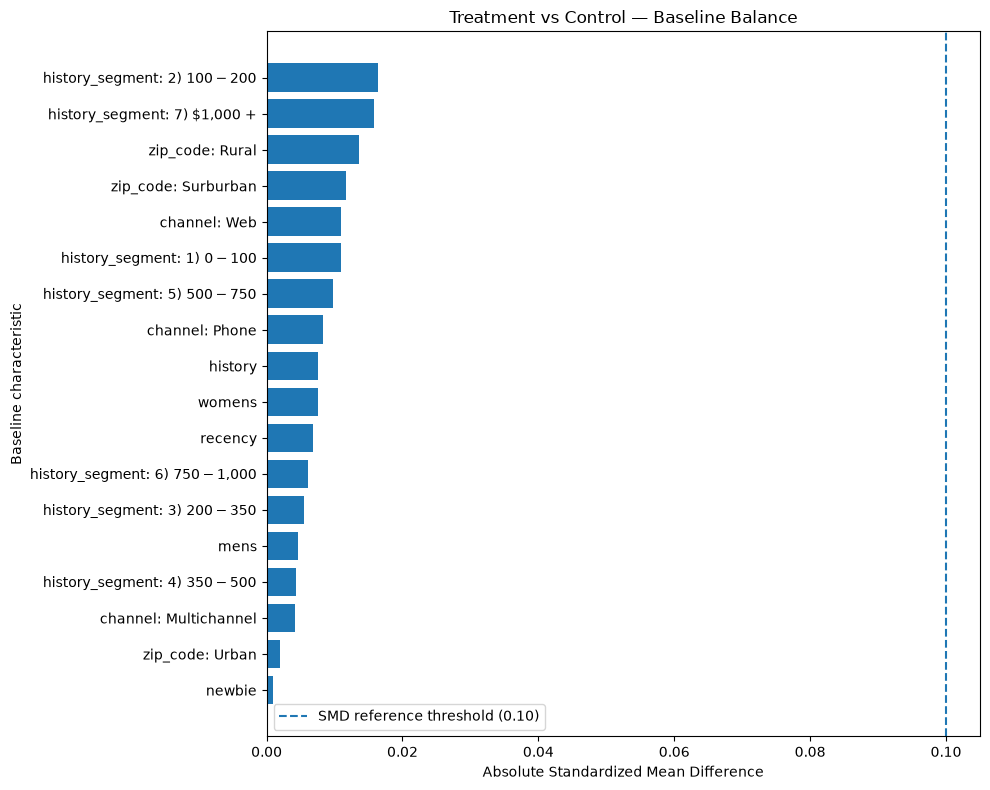

In [7]:
# Combine numeric and categorical SMD results
numeric_plot = smd_df[["feature", "absolute_smd"]].copy()
numeric_plot["category"] = ""

categorical_plot = categorical_smd_df[
    ["feature", "category", "absolute_smd"]
].copy()

all_smd = pd.concat(
    [numeric_plot, categorical_plot],
    ignore_index=True
)

# Create readable labels
all_smd["label"] = all_smd.apply(
    lambda row: (
        f"{row['feature']}: {row['category']}"
        if row["category"]
        else row["feature"]
    ),
    axis=1
)

all_smd = all_smd.sort_values("absolute_smd")

plt.figure(figsize=(10, 8))

plt.barh(
    all_smd["label"],
    all_smd["absolute_smd"]
)

plt.axvline(
    x=0.10,
    linestyle="--",
    label="SMD reference threshold (0.10)"
)

plt.xlabel("Absolute Standardized Mean Difference")
plt.ylabel("Baseline characteristic")
plt.title("Treatment vs Control — Baseline Balance")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "baseline_balance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Baseline balance findings

- Treatment and control groups have nearly identical sample sizes.
- Numeric and binary baseline characteristics have very small SMDs.
- Categorical baseline characteristics also have very small SMDs.
- The largest absolute SMD across the measured characteristics is 0.0164.
- All measured baseline characteristics are below the 0.10 diagnostic threshold.

Conclusion: The treatment and control groups appear highly comparable
on the observed pre-treatment characteristics. This supports the
planned comparison but does not independently prove random assignment
or eliminate the possibility of unmeasured confounding.

## 5. Campaign outcome analysis

Compare treatment and control groups on:
- Website visit rate
- Conversion rate
- Average spend per customer

These are post-treatment outcomes, not baseline characteristics.

In [9]:
outcome_summary = (
    analysis_df
    .groupby("treatment")
    .agg(
        customers=("conversion", "size"),
        visits=("visit", "sum"),
        visit_rate=("visit", "mean"),
        conversions=("conversion", "sum"),
        conversion_rate=("conversion", "mean"),
        total_spend=("spend", "sum"),
        average_spend=("spend", "mean"),
        median_spend=("spend", "median"),
    )
)

outcome_summary.index = ["Control", "Treatment"]

print(outcome_summary.round(4).to_string())

           customers  visits  visit_rate  conversions  conversion_rate  total_spend  average_spend  median_spend
Control        21306    2262      0.1062          122           0.0057     13908.33         0.6528           0.0
Treatment      21307    3894      0.1828          267           0.0125     30311.69         1.4226           0.0


## 6. Descriptive treatment effect calculations

Calculate absolute differences and relative lift for
visits, conversions, and average spending.

In [10]:
control = analysis_df[analysis_df["treatment"] == 0]
treatment = analysis_df[analysis_df["treatment"] == 1]

# Calculate outcome rates and average spending
metrics = {
    "Visit rate": (
        control["visit"].mean(),
        treatment["visit"].mean()
    ),
    "Conversion rate": (
        control["conversion"].mean(),
        treatment["conversion"].mean()
    ),
    "Average spend per customer": (
        control["spend"].mean(),
        treatment["spend"].mean()
    ),
}

results = []

for metric, (control_value, treatment_value) in metrics.items():
    absolute_difference = treatment_value - control_value

    relative_lift = (
        absolute_difference / control_value * 100
        if control_value != 0 else np.nan
    )

    results.append({
        "metric": metric,
        "control": control_value,
        "treatment": treatment_value,
        "absolute_difference": absolute_difference,
        "relative_lift_pct": relative_lift,
    })

effect_summary = pd.DataFrame(results)

print(effect_summary.round(4).to_string(index=False))

                    metric  control  treatment  absolute_difference  relative_lift_pct
                Visit rate   0.1062     0.1828               0.0766            72.1405
           Conversion rate   0.0057     0.0125               0.0068           118.8422
Average spend per customer   0.6528     1.4226               0.7698           117.9289


## 7. Statistical inference for conversion

Primary outcome: conversion

- Null hypothesis (H0): Treatment and control conversion rates are equal.
- Alternative hypothesis (H1): Treatment and control conversion rates differ.
- Significance level: 0.05
- Confidence level: 95%

In [11]:
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep,
)

# Observed conversion counts and sample sizes
treatment_conversions = int(treatment["conversion"].sum())
control_conversions = int(control["conversion"].sum())

treatment_n = len(treatment)
control_n = len(control)

# Two-sided two-proportion z-test
count = [treatment_conversions, control_conversions]
nobs = [treatment_n, control_n]

z_stat, p_value = proportions_ztest(
    count,
    nobs,
    alternative="two-sided"
)

# 95% confidence interval for treatment minus control
ci_low, ci_high = confint_proportions_2indep(
    count1=treatment_conversions,
    nobs1=treatment_n,
    count2=control_conversions,
    nobs2=control_n,
    method="newcomb",
    alpha=0.05,
)

observed_difference = (
    treatment_conversions / treatment_n
    - control_conversions / control_n
)

print("========== CONVERSION INFERENCE ==========")
print(f"Treatment conversions: {treatment_conversions}/{treatment_n}")
print(f"Control conversions: {control_conversions}/{control_n}")
print(f"Observed difference: {observed_difference:.6f}")
print(f"95% confidence interval: [{ci_low:.6f}, {ci_high:.6f}]")
print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.8f}")

if p_value < 0.05:
    print("Result: Reject the null hypothesis at the 5% level.")
else:
    print("Result: Fail to reject the null hypothesis at the 5% level.")

========== CONVERSION INFERENCE ==========
Treatment conversions: 267/21307
Control conversions: 122/21306
Observed difference: 0.006805
95% confidence interval: [0.005014, 0.008641]
Z-statistic: 7.3851
P-value: 0.00000000
Result: Reject the null hypothesis at the 5% level.


### Conversion inference findings

- Treatment conversion rate: 1.2531%
- Control conversion rate: 0.5726%
- Absolute difference: approximately 0.6805 percentage points
- 95% confidence interval: [0.5014, 0.8641] percentage points
- Two-proportion z-statistic: 7.3851
- P-value: approximately 1.5e-13

The conversion-rate difference is statistically significant at the
5% significance level.

The confidence interval is entirely above zero, supporting a
positive treatment-control difference under the test assumptions.

This is an average group-level comparison, not an individualized
uplift estimate. Causal interpretation remains conditional on
the experiment design and data assumptions.

## 8. Bootstrap inference for average spending

Primary business-value metric: average spend per customer.

Estimate the treatment-control difference using bootstrap
resampling and a 95% percentile confidence interval.

Resample customers independently within each experiment group.

In [13]:
# Bootstrap confidence interval for average spend difference

RANDOM_SEED = 42
N_BOOTSTRAPS = 10_000

control_spend = control["spend"].to_numpy()
treatment_spend = treatment["spend"].to_numpy()

rng = np.random.default_rng(RANDOM_SEED)

observed_spend_difference = (
    treatment_spend.mean() - control_spend.mean()
)

bootstrap_differences = np.empty(N_BOOTSTRAPS)

for i in range(N_BOOTSTRAPS):
    control_sample = rng.choice(
        control_spend,
        size=len(control_spend),
        replace=True,
    )

    treatment_sample = rng.choice(
        treatment_spend,
        size=len(treatment_spend),
        replace=True,
    )

    bootstrap_differences[i] = (
        treatment_sample.mean() - control_sample.mean()
    )

ci_low, ci_high = np.percentile(
    bootstrap_differences,
    [2.5, 97.5],
)

print("========== SPENDING BOOTSTRAP ==========")
print(f"Control average spend: ${control_spend.mean():.4f}")
print(f"Treatment average spend: ${treatment_spend.mean():.4f}")
print(
    f"Observed difference: "
    f"${observed_spend_difference:.4f} per customer"
)
print(
    f"95% bootstrap confidence interval: "
    f"[${ci_low:.4f}, ${ci_high:.4f}]"
)
print(f"Bootstrap iterations: {N_BOOTSTRAPS}")
print(f"Random seed: {RANDOM_SEED}")

========== SPENDING BOOTSTRAP ==========
Control average spend: $0.6528
Treatment average spend: $1.4226
Observed difference: $0.7698 per customer
95% bootstrap confidence interval: [$0.4874, $1.0614]
Bootstrap iterations: 10000
Random seed: 42


### Spending inference findings

- Control average spend per customer: $0.6528
- Treatment average spend per customer: $1.4226
- Observed difference: +$0.7698 per customer
- 95% bootstrap confidence interval: [$0.4874, $1.0614]
- Bootstrap iterations: 10,000
- Random seed: 42

The treatment group has higher average spending per customer.
The bootstrap confidence interval is entirely above zero,
supporting a positive group-level spending difference.

Spending is highly skewed, with a median of zero in both groups.
The mean is therefore used to capture overall spending per customer.

This result is descriptive and conditional on the experiment
design and independence assumptions. It does not account for
campaign costs or profit margins.

## 9. Campaign outcome visualizations

Compare treatment and control on website visits,
conversion rates, and average spending per customer.

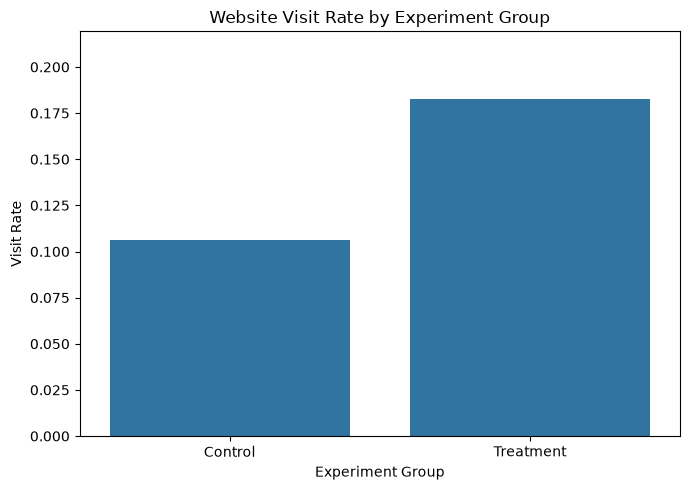

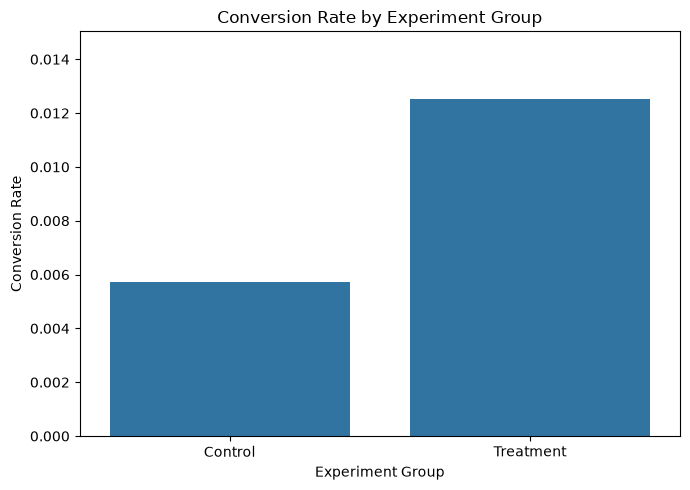

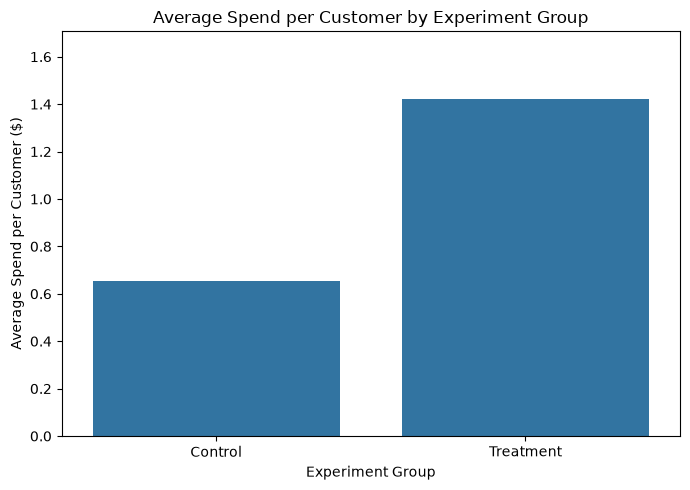

In [14]:
# Prepare chart data
plot_data = outcome_summary[
    ["visit_rate", "conversion_rate", "average_spend"]
].copy()

plot_data.index.name = "group"

# 1. Visit rate
plt.figure(figsize=(7, 5))
sns.barplot(
    data=plot_data.reset_index(),
    x="group",
    y="visit_rate",
)

plt.title("Website Visit Rate by Experiment Group")
plt.xlabel("Experiment Group")
plt.ylabel("Visit Rate")
plt.ylim(0, plot_data["visit_rate"].max() * 1.2)
plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "visit_rate_by_group.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# 2. Conversion rate
plt.figure(figsize=(7, 5))
sns.barplot(
    data=plot_data.reset_index(),
    x="group",
    y="conversion_rate",
)

plt.title("Conversion Rate by Experiment Group")
plt.xlabel("Experiment Group")
plt.ylabel("Conversion Rate")
plt.ylim(0, plot_data["conversion_rate"].max() * 1.2)
plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "conversion_rate_by_group.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# 3. Average spend per customer
plt.figure(figsize=(7, 5))
sns.barplot(
    data=plot_data.reset_index(),
    x="group",
    y="average_spend",
)

plt.title("Average Spend per Customer by Experiment Group")
plt.xlabel("Experiment Group")
plt.ylabel("Average Spend per Customer ($)")
plt.ylim(0, plot_data["average_spend"].max() * 1.2)
plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "average_spend_by_group.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()